Офлайн-пересчёт накопленной контрольной точки 200 задач из сохранённых разборов и аудитов. Новых агентов и сети нет; изменение исходных хешей останавливает пересчёт.

In [1]:
import sys
from pathlib import Path
from IPython.display import display, Image, Markdown
root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'scripts/fipi_checkpoint200.py').is_file())
sys.path.insert(0, str(root / 'scripts'))
import fipi_checkpoint200 as cp
data = cp.collect()
assert data['input_digest'] == '0ab9023e7ed8d75eeb8b532956fa34913dfcd0a0a66aba1426d9b33d4ac79498', 'Saved inputs changed: use the code version recorded for this snapshot'
summary, tables = cp.metrics(data)
checks = cp.self_checks(data)
report_path = root / 'data/annotation/analyses/2026-11-09-fipi-checkpoint-200-v1'
if not report_path.exists():
    report_path = report_path.with_name(report_path.name + '.building')
checks


Frozen bytes verified, including archived paths.


{'eda100_summary_reproduced': True,
 'eda100_frequencies_reproduced': True,
 'eda150_node_frequencies_reproduced': True,
 'eda150_included_tasks': 148}

In [2]:
lines = ['| Слой | Отобрано | В частотах | Подтверждённых узлов | Единичные |', '|---|---:|---:|---:|---:|']
for key, name in cp.POPULATIONS.items():
    s = summary[key]
    lines.append(f"| {name} | {s['selected_n']} | {s['included_n']} | {s['confirmed_catalog_nodes']} | {s['singleton_nodes']['numerator']} |")
display(Markdown('\n'.join(lines)))


| Слой | Отобрано | В частотах | Подтверждённых узлов | Единичные |
|---|---:|---:|---:|---:|
| Исходные 50: редакторские связи | 50 | 49 | 136 | 101 |
| Первые 50 новых (запуск 2026-11-02): агентный аудит | 50 | 49 | 48 | 30 |
| Бронь Bogdan108, 100 задач (партии 5–12): агентный аудит | 100 | 100 | 65 | 34 |
| Бронь, партия 5: Opus, уровень рассуждений по умолчанию | 15 | 15 | 24 | 19 |
| Бронь, партии 6–12: Opus, effort low | 85 | 85 | 54 | 29 |
| Все новые 150: агентный аудит | 150 | 149 | 81 | 33 |
| Смешанный накопленный корпус 200 | 200 | 198 | 139 | 55 |

In [3]:
{k: summary[k]['audit_statuses'] for k in ('ext_new50', 'team100', 'team_b5_default', 'team_b6_12_low')}

{'ext_new50': {'match': {'numerator': 87, 'denominator': 199},
  'new_candidate': {'numerator': 62, 'denominator': 199},
  'needs_split': {'numerator': 41, 'denominator': 199},
  'uncertain': {'numerator': 9, 'denominator': 199}},
 'team100': {'match': {'numerator': 142, 'denominator': 374},
  'new_candidate': {'numerator': 141, 'denominator': 374},
  'needs_split': {'numerator': 70, 'denominator': 374},
  'uncertain': {'numerator': 21, 'denominator': 374}},
 'team_b5_default': {'match': {'numerator': 29, 'denominator': 75},
  'new_candidate': {'numerator': 31, 'denominator': 75},
  'needs_split': {'numerator': 11, 'denominator': 75},
  'uncertain': {'numerator': 4, 'denominator': 75}},
 'team_b6_12_low': {'match': {'numerator': 113, 'denominator': 299},
  'new_candidate': {'numerator': 110, 'denominator': 299},
  'needs_split': {'numerator': 59, 'denominator': 299},
  'uncertain': {'numerator': 17, 'denominator': 299}}}

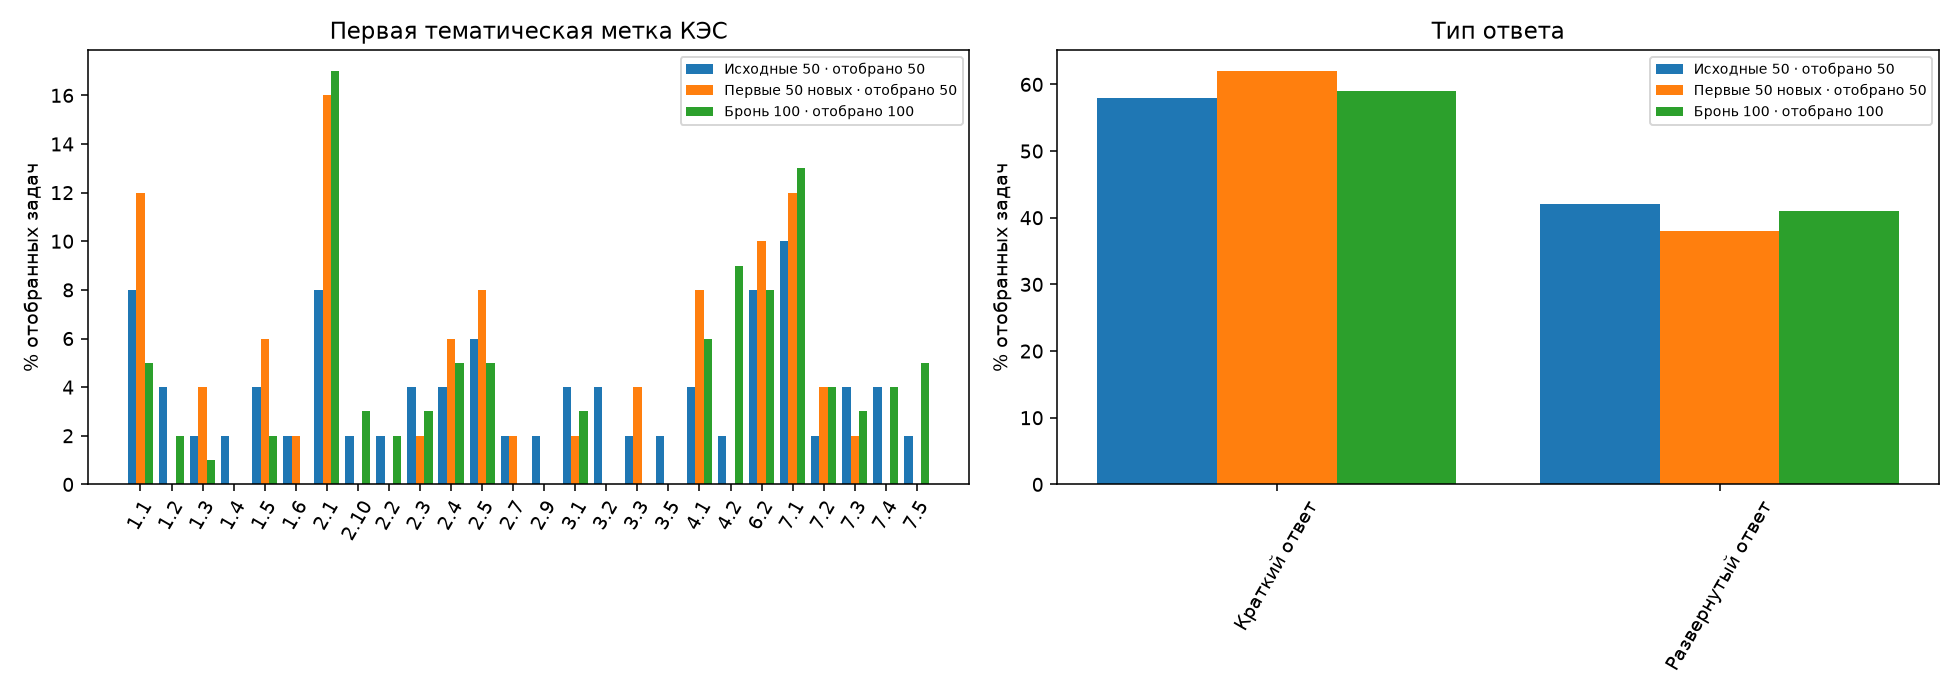

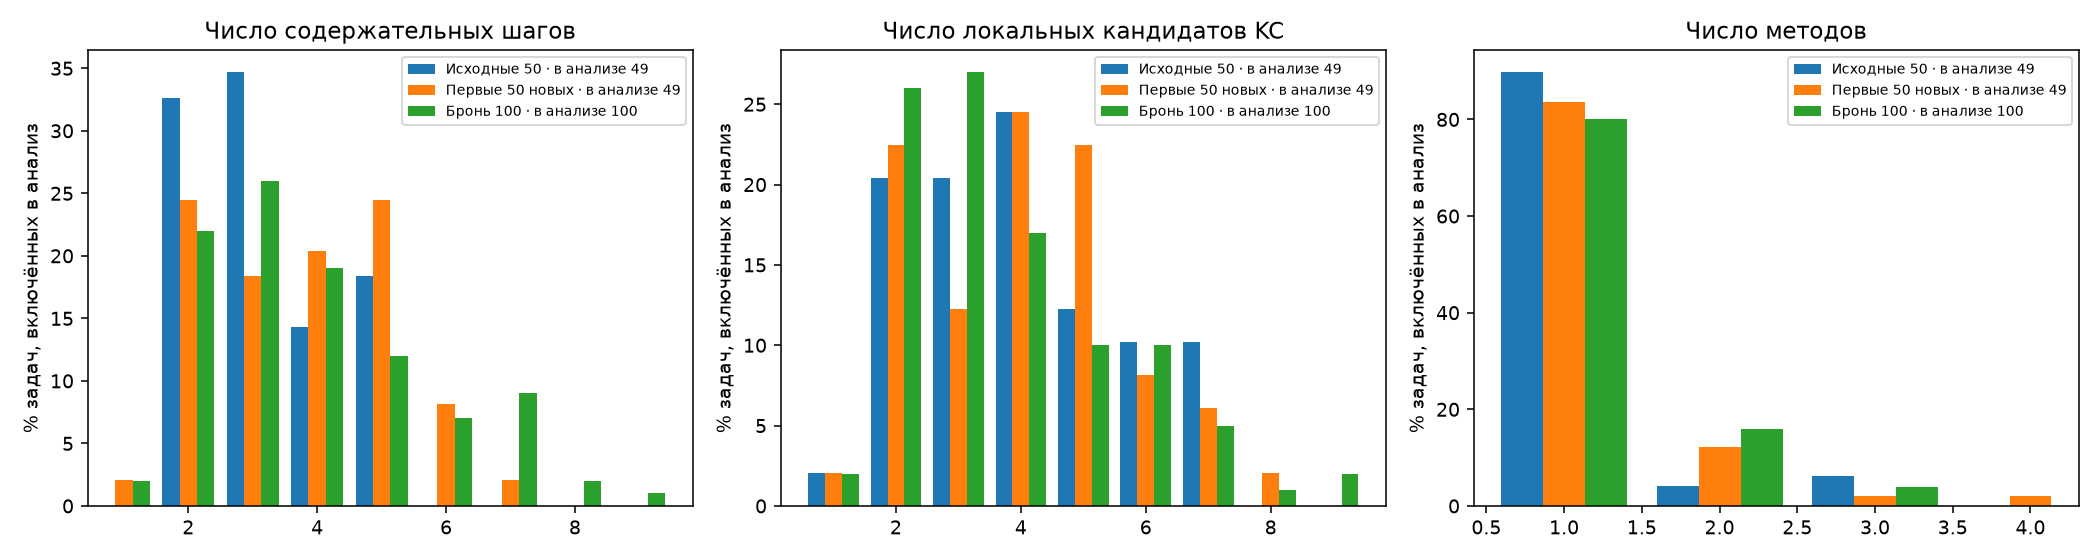

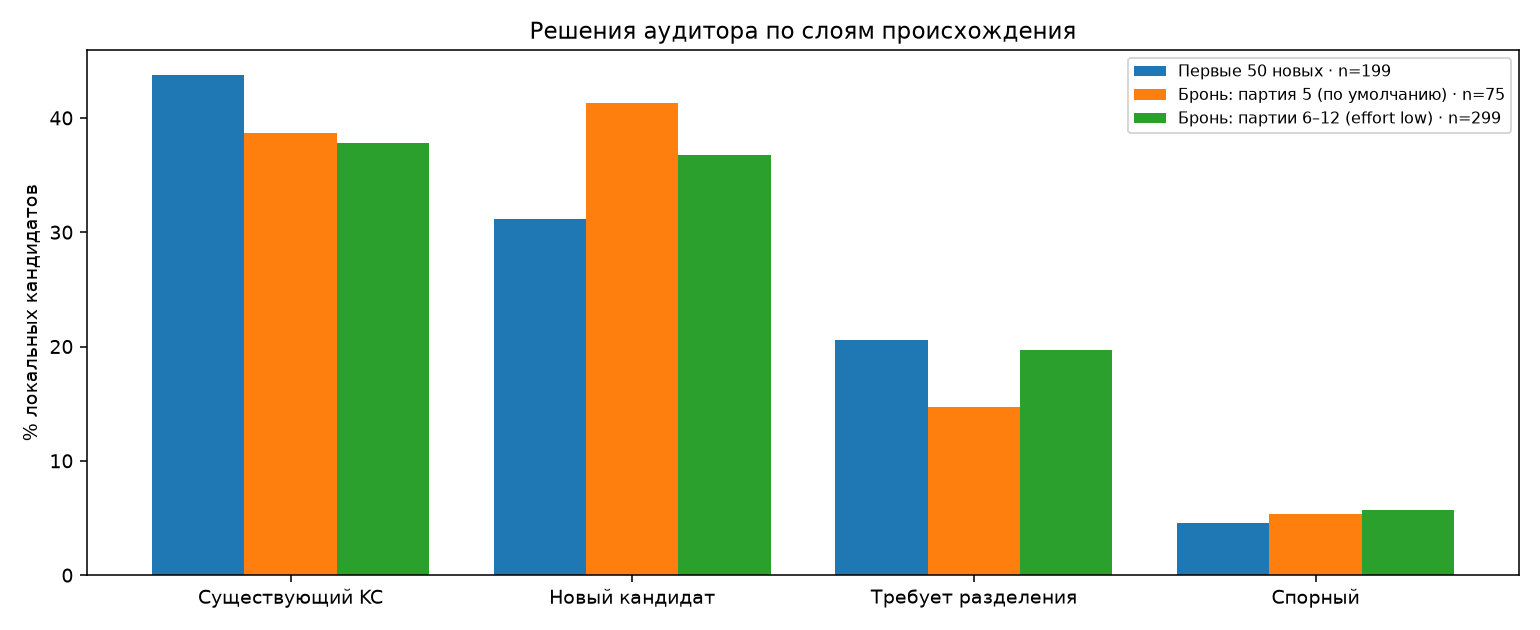

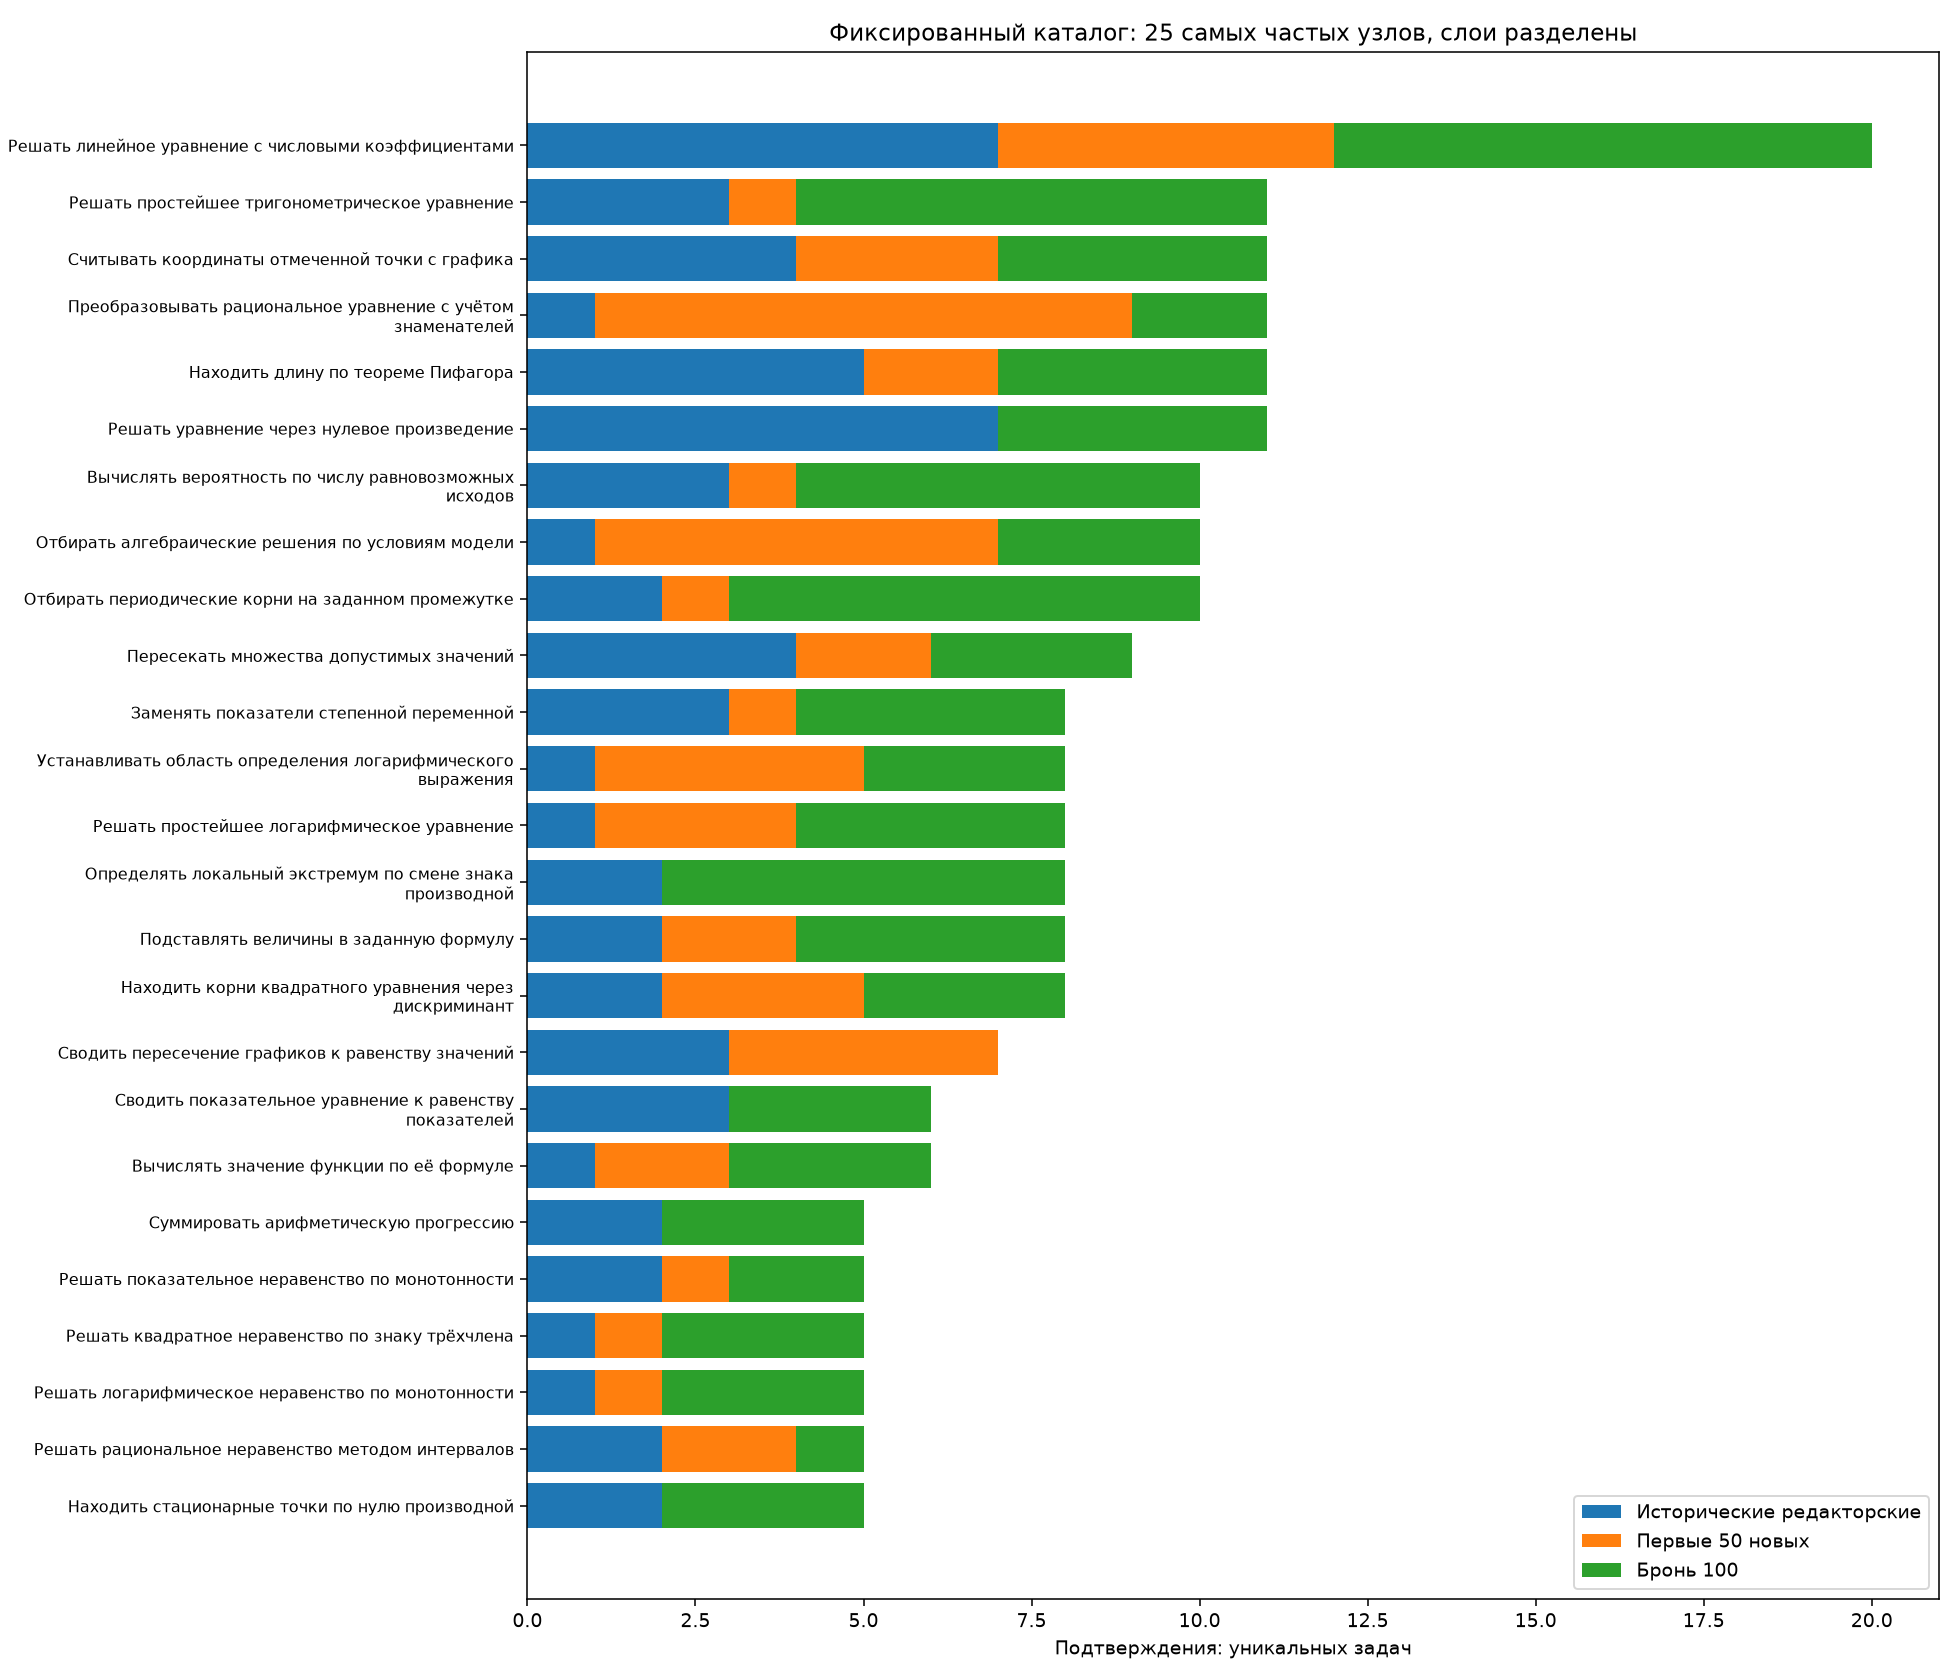

In [4]:
for name in ['01-composition', '02-structure', '03-audit-statuses', '04-catalog-evidence']:
    display(Image(filename=str(report_path / 'figures' / (name + '.png'))))
